# SciBERT: contexto + documento citado (A/B)

- Contexto: solo el contexto de cita.
- A: contexto de cita + título + abstract del citado.
- B: contexto de cita + Top-3 chunks del citado con su sección.

Librerías necesarias para ejecutar este notebook (Python 3.12):

- torch 2.10.0
- transformers 5.20.2
- numpy 2.4.2
- pandas 3.1.0
- scikit-learn 1.8.0
- matplotlib 3.10.8
- mlflow 3.17.2

In [1]:
from pathlib import Path
import hashlib, json, os, re, time, platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
import mlflow

hf_logging.set_verbosity_error()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/dataset/train.jsonl').exists())
DATA = ROOT/'data/dataset'
RUN_NAME = os.environ.get('RUN_NAME') or datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT = ROOT/'mlruns/scibert_ab'/RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
LABELS = ['Background','Uses','Comparison','Extends','Motivation','Future Work','Evidence','Originator','Further Reading']
K = len(LABELS)
LABEL2ID = {l:i for i,l in enumerate(LABELS)}
MODEL_NAME = 'allenai/scibert_scivocab_uncased'
STRATEGIES = ['contexto','A','B']
SEEDS = [42, 43, 44]
HP = {'lr':2e-5,'epochs':5,'patience':2,'batch_size':8,'grad_accum':2,'eval_batch_size':32,'warmup_ratio':0.1,'weight_decay':0.01,'max_length':512,'max_grad_norm':1.0}
SMOKE = os.environ.get('SMOKE') == '1'
if SMOKE:
    SEEDS, HP = SEEDS[:1], {**HP,'epochs':1}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
VERSIONS = {p:version(p) for p in ['torch','transformers','numpy','pandas','scikit-learn','mlflow']}
display(pd.Series({**VERSIONS,'python':platform.python_version(),'device':str(DEVICE),'run':RUN_NAME}, name='valor').to_frame())
mlflow.set_tracking_uri('sqlite:///' + (ROOT/'mlruns/scibert_ab/mlflow.db').as_posix())
mlflow.set_experiment('EvidenCite-SciBERT-AB')

/Users/jtorresor/.cache/uv/archive-v0/AIQUFA_4j3T0Lv5a/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/23 18:45:00 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/jtorresor/.cache/uv/archive-v0/AIQUFA_4j3T0Lv5a/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,valor
torch,2.10.0
transformers,5.20.2
numpy,2.4.2
pandas,3.1.0
scikit-learn,1.8.0
mlflow,3.17.2
python,3.12.10
device,mps
run,completo_20261023


2026/10/23 18:45:00 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/23 18:45:00 INFO mlflow.store.db.utils: Updating database tables


2026/10/23 18:45:01 INFO mlflow.tracking.fluent: Experiment with name 'EvidenCite-SciBERT-AB' does not exist. Creating a new experiment.


<Experiment: artifact_location='/Users/jtorresor/MAIA_Proyectos_Desarrollo_Soluciones/Proyecto_grado/notebooks/mlruns/1', creation_time=1792799101218, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792799101218, lifecycle_stage='active', name='EvidenCite-SciBERT-AB', tags={}, trace_location=None, workspace='default'>

In [2]:
splits = {s:[json.loads(line) for line in (DATA/f'{s}.jsonl').read_text().splitlines() if line.strip()] for s in ['train','dev','test']}
if SMOKE:
    splits = {s:rows[:64] for s,rows in splits.items()}
hashes = {s:hashlib.sha256((DATA/f'{s}.jsonl').read_bytes()).hexdigest() for s in splits}
assert all(r['label'] in LABELS for rows in splits.values() for r in rows)
for a,b in [('train','dev'),('train','test'),('dev','test')]:
    assert not ({r['citing_paper']['id'] for r in splits[a]} & {r['citing_paper']['id'] for r in splits[b]}), f'Solapamiento {a}/{b}'
y = {s:np.array([r['label'] for r in rows]) for s,rows in splits.items()}
ids = {s:np.array([LABEL2ID[l] for l in labels]) for s,labels in y.items()}
groups_test = np.array([r['citing_paper']['id'] for r in splits['test']])
counts = pd.DataFrame({s:pd.Series(labels).value_counts() for s,labels in y.items()}).reindex(LABELS).fillna(0).astype(int)
display(counts)
train_counts = np.bincount(ids['train'], minlength=K)
CLASS_WEIGHTS = torch.tensor(len(ids['train'])/(K*np.maximum(train_counts,1)), dtype=torch.float32)
manifest = {'sha256':hashes,'versions':VERSIONS,'python':platform.python_version(),'device':str(DEVICE),'model':MODEL_NAME,'labels':LABELS,'seeds':SEEDS,'hp':HP,'smoke':SMOKE,'class_counts':counts.to_dict(),'class_weights':dict(zip(LABELS,CLASS_WEIGHTS.tolist()))}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')

,train,dev,test
Background,612,113,149
Uses,556,172,167
Comparison,422,129,121
Extends,149,29,20
Motivation,85,28,29
Future Work,8,2,0
Evidence,156,0,0
Originator,26,0,0
Further Reading,241,18,0


2069

In [3]:
def section(name):
    return '' if not name or name == 'Unknown Section' else f'[{name}] '

def citing_text(r):
    return section(r['citing_paper']['rhetorical_section']) + r['citation_context']

def cited_text(r, strategy):
    cited = r['cited_paper']
    if strategy == 'A':
        return f"{cited['title']}. {cited['abstract']}"
    chunks = sorted(cited['retrieved_chunks'], key=lambda c:c.get('rank',999))[:3]
    return ' '.join(section(c['section_heading']) + c['text'] for c in chunks)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(rows, strategy, truncate=True):
    first = [citing_text(r) for r in rows]
    if strategy == 'contexto':
        return tokenizer(first, truncation=truncate, max_length=HP['max_length'] if truncate else None)
    second = [cited_text(r, strategy) for r in rows]
    return tokenizer(first, second, truncation='longest_first' if truncate else False, max_length=HP['max_length'] if truncate else None)

encoded, length_stats = {}, []
for strategy in STRATEGIES:
    encoded[strategy] = {}
    for s, rows in splits.items():
        encoded[strategy][s] = encode(rows, strategy)
        full = np.array([len(x) for x in encode(rows, strategy, truncate=False)['input_ids']])
        length_stats.append({'estrategia':strategy,'split':s,'media':full.mean(),'p50':np.percentile(full,50),'p95':np.percentile(full,95),'max':full.max(),'truncados_%':100*(full>HP['max_length']).mean()})
length_stats = pd.DataFrame(length_stats)
display(length_stats.round(1))
length_stats.to_csv(OUT/'token_lengths.csv', index=False)

,estrategia,split,media,p50,p95,max,truncados_%
0,contexto,train,128.2,118.0,216.0,662,0.2
1,contexto,dev,114.1,109.0,176.5,244,0.0
2,contexto,test,114.5,109.5,184.8,236,0.0
3,A,train,335.0,323.0,521.3,910,5.5
4,A,dev,273.8,291.0,410.0,519,0.2
5,A,test,299.6,309.5,485.2,567,2.3
6,B,train,528.7,508.0,689.0,2930,47.4
7,B,dev,499.1,496.0,604.5,764,38.1
8,B,test,500.1,513.0,616.2,788,50.2


In [4]:
def make_loader(enc, labels, shuffle, seed):
    items = [{**{k:enc[k][i] for k in enc.keys()}, 'labels':int(labels[i])} for i in range(len(labels))]
    return DataLoader(items, batch_size=HP['batch_size'] if shuffle else HP['eval_batch_size'], shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), collate_fn=lambda b:tokenizer.pad(b, pad_to_multiple_of=64, return_tensors='pt'))

def predict_proba(model, loader):
    model.eval(); out = []
    with torch.no_grad():
        for batch in loader:
            batch = {k:v.to(DEVICE) for k,v in batch.items() if k != 'labels'}
            with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
                logits = model(**batch).logits
            out.append(torch.softmax(logits.float(), -1).cpu())
    return torch.cat(out).numpy()

def metrics(truth, pred):
    return {'accuracy':accuracy_score(truth,pred),'f1_macro_9':f1_score(truth,pred,labels=LABELS,average='macro',zero_division=0),
            'f1_macro_present':f1_score(truth,pred,labels=sorted(set(truth)),average='macro',zero_division=0),
            'f1_weighted':f1_score(truth,pred,average='weighted',zero_division=0)}

def train_run(strategy, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=K, id2label=dict(enumerate(LABELS)), label2id=LABEL2ID).to(DEVICE)
    train_loader = make_loader(encoded[strategy]['train'], ids['train'], True, seed)
    dev_loader = make_loader(encoded[strategy]['dev'], ids['dev'], False, seed)
    test_loader = make_loader(encoded[strategy]['test'], ids['test'], False, seed)
    updates = -(-len(train_loader)//HP['grad_accum']) * HP['epochs']
    optimizer = torch.optim.AdamW(model.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
    scheduler = get_linear_schedule_with_warmup(optimizer, int(HP['warmup_ratio']*updates), updates)
    loss_fn = torch.nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    best_score, best_state, best_epoch, wait, history = -1.0, None, 0, 0, []
    start = time.perf_counter()
    for epoch in range(1, HP['epochs']+1):
        model.train(); total = torch.zeros((), device=DEVICE)
        for step, batch in enumerate(train_loader):
            batch = {k:v.to(DEVICE) for k,v in batch.items()}
            labels = batch.pop('labels')
            with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss/HP['grad_accum']).backward()
            total += loss.detach()
            if (step+1) % HP['grad_accum'] == 0 or step+1 == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), HP['max_grad_norm'])
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
        dev_scores = metrics(y['dev'], np.array(LABELS)[predict_proba(model, dev_loader).argmax(1)])
        history.append({'epoch':epoch,'train_loss':total.item()/len(train_loader),**{f'dev_{k}':v for k,v in dev_scores.items()},'seconds':time.perf_counter()-start})
        print(strategy, seed, history[-1])
        if dev_scores['f1_macro_9'] > best_score:
            best_score, best_epoch, wait = dev_scores['f1_macro_9'], epoch, 0
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= HP['patience']:
                break
    train_seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    start = time.perf_counter()
    proba = predict_proba(model, test_loader)
    latency = (time.perf_counter()-start)/len(ids['test'])
    return model, proba, history, best_epoch, best_score, train_seconds, latency

In [5]:
results, histories, probas = [], {}, {}
best_dev = {}
for strategy in STRATEGIES:
    for seed in SEEDS:
        key = f'{strategy}_s{seed}'
        if (OUT/f'{key}.json').exists():
            saved = json.loads((OUT/f'{key}.json').read_text())
            results.append(saved['result']); histories[key] = saved['history']
            probas[key] = pd.read_csv(OUT/f'predictions_{key}.csv')[LABELS].to_numpy()
            continue
        with mlflow.start_run(run_name=key):
            mlflow.log_params({**HP,'strategy':strategy,'seed':seed,'model':MODEL_NAME,'selection_metric':'dev_f1_macro_9','smoke':SMOKE})
            model, proba, history, best_epoch, best_score, train_seconds, latency = train_run(strategy, seed)
            for h in history:
                mlflow.log_metrics({k:v for k,v in h.items() if k != 'epoch'}, step=h['epoch'])
            pred = np.array(LABELS)[proba.argmax(1)]
            test_scores = metrics(y['test'], pred)
            result = {'strategy':strategy,'seed':seed,'best_epoch':best_epoch,'dev_f1_macro_9':best_score,**{f'test_{k}':v for k,v in test_scores.items()},
                      'train_seconds':train_seconds,'latency_ms':1000*latency,'run_id':mlflow.active_run().info.run_id}
            mlflow.log_metrics({k:v for k,v in result.items() if k.startswith('test_') or k in ['train_seconds','latency_ms','best_epoch']})
            frame = pd.DataFrame(proba, columns=LABELS)
            frame.insert(0,'prediction',pred); frame.insert(0,'truth',y['test']); frame.insert(0,'citing_paper_id',groups_test)
            frame.insert(0,'instance_id',[r['instance_id'] for r in splits['test']])
            frame.to_csv(OUT/f'predictions_{key}.csv', index=False)
            mlflow.log_artifact(str(OUT/f'predictions_{key}.csv'))
            (OUT/f'{key}.json').write_text(json.dumps({'result':result,'history':history},indent=2),encoding='utf-8')
            if not SMOKE and best_score > best_dev.get(strategy,-1.0):
                best_dev[strategy] = best_score
                target = ROOT/'models'/{'A':'baseline_config_a','B':'baseline_config_b'}.get(strategy,'scibert_contexto')
                model.save_pretrained(target); tokenizer.save_pretrained(target)
            results.append(result); histories[key] = history; probas[key] = proba
            del model
            if DEVICE.type == 'mps': torch.mps.empty_cache()
            if DEVICE.type == 'cuda': torch.cuda.empty_cache()
results = pd.DataFrame(results)
display(results.round(4))
results.to_csv(OUT/'runs.csv', index=False)

W1023 18:45:03.756000 34081 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 49540.98it/s]

contexto 42 {'epoch': 1, 'train_loss': 1.7112718947390293, 'dev_accuracy': 0.5824847250509165, 'dev_f1_macro_9': 0.3267260486080711, 'dev_f1_macro_present': 0.42007634821037704, 'dev_f1_weighted': 0.5577918172317929, 'seconds': 629.5056304579921}


contexto 42 {'epoch': 2, 'train_loss': 0.9807878859499668, 'dev_accuracy': 0.6415478615071283, 'dev_f1_macro_9': 0.4096031731024592, 'dev_f1_macro_present': 0.5266326511317333, 'dev_f1_weighted': 0.6557099389399766, 'seconds': 1194.3150622499961}


...

B 44 {'epoch': 2, 'train_loss': 1.0463000358419214, 'dev_accuracy': 0.6639511201629328, 'dev_f1_macro_9': 0.39618151910508737, 'dev_f1_macro_present': 0.509376238849398, 'dev_f1_weighted': 0.6460443369780002, 'seconds': 1222.6388504170172}


B 44 {'epoch': 3, 'train_loss': 0.7079119851403203, 'dev_accuracy': 0.6456211812627292, 'dev_f1_macro_9': 0.4047134731051434, 'dev_f1_macro_present': 0.5203458939923272, 'dev_f1_weighted': 0.6506795538935837, 'seconds': 1847.8303043750057}


B 44 {'epoch': 4, 'train_loss': 0.5262919216291279, 'dev_accuracy': 0.6232179226069247, 'dev_f1_macro_9': 0.47933331396942436, 'dev_f1_macro_present': 0.6162856893892599, 'dev_f1_weighted': 0.6409106726160119, 'seconds': 2469.1440558750182}


B 44 {'epoch': 5, 'train_loss': 0.40815956710923645, 'dev_accuracy': 0.6720977596741344, 'dev_f1_macro_9': 0.49647664369249483, 'dev_f1_macro_present': 0.6383271133189219, 'dev_f1_weighted': 0.6706694996856989, 'seconds': 3098.9110749170068}


,strategy,seed,best_epoch,dev_f1_macro_9,test_accuracy,test_f1_macro_9,test_f1_macro_present,test_f1_weighted,train_seconds,latency_ms,run_id
0,contexto,42,5,0.5036,0.5864,0.2659,0.4787,0.5866,3124.0949,39.0788,576333ecf7f34cda9495a0defa86f738
1,contexto,43,5,0.4835,0.5802,0.2651,0.4772,0.5865,2695.2192,38.5317,cb47dfa4308841f19a0d5287e5ee80eb
2,contexto,44,4,0.5213,0.5453,0.2563,0.4614,0.5611,3100.9385,34.9818,a1e61550ed76409785ea9f236af57578
3,A,42,5,0.4233,0.5905,0.2590,0.4661,0.5911,8194.7023,120.2905,1aa0dbc688eb4178803d6cde228708e4
4,A,43,5,0.4713,0.5844,0.2596,0.4672,0.5880,6819.7319,69.0957,6cf1e951983641a2ad52015d77b0f7b0
5,A,44,4,0.4986,0.5514,0.2649,0.4768,0.5753,5915.3344,80.9831,924e272f02fb47d88d95f721758619d7
6,B,42,5,0.4989,0.5741,0.2613,0.4704,0.5787,3050.2453,74.8265,36ca542980404b5d949f8cf4659bb7a2
7,B,43,5,0.4973,0.5617,0.2519,0.4534,0.5769,3052.5955,74.1748,433dd721fd454161acbe08e75b23592f
8,B,44,5,0.4965,0.5638,0.2504,0.4507,0.5680,3099.0742,77.4586,eb05dcf8fdc1414e9fffae7583b894bd


In [6]:
def tfidf_text(row, strategy):
    context = re.sub(r'</?cite>', '', row['citation_context'])
    cited = row['cited_paper']
    evidence = [cited['title'], cited['abstract']] if strategy=='A' else [c['text'] for c in sorted(cited['retrieved_chunks'],key=lambda c:c.get('rank',999))[:3]]
    return '\n'.join([context,*evidence])

TFIDF_CONFIGS = [{'config':'r1','ngram_max':1,'min_df':1,'C':0.5},{'config':'r2','ngram_max':2,'min_df':2,'C':1.0},{'config':'r3','ngram_max':2,'min_df':3,'C':2.0}]
tfidf_preds, tfidf_rows = {}, []
for strategy in ['A','B']:
    X = {s:[tfidf_text(r,strategy) for r in rows] for s,rows in splits.items()}
    best = None
    for config in TFIDF_CONFIGS:
        model = Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,config['ngram_max']),min_df=config['min_df'],max_features=100000,sublinear_tf=True)),
                          ('classifier',LogisticRegression(C=config['C'],class_weight='balanced',solver='lbfgs',max_iter=2000,random_state=42))]).fit(X['train'],y['train'])
        score = metrics(y['dev'], model.predict(X['dev']))['f1_macro_9']
        if best is None or score > best[0]:
            best = (score, config['config'], model)
    tfidf_preds[f'tfidf_{strategy}'] = best[2].predict(X['test'])
    tfidf_rows.append({'modelo':f'tfidf_{strategy}','config':best[1],**metrics(y['test'], tfidf_preds[f'tfidf_{strategy}'])})
display(pd.DataFrame(tfidf_rows).round(4))

,modelo,config,accuracy,f1_macro_9,f1_macro_present,f1_weighted
0,tfidf_A,r3,0.3745,0.1663,0.2993,0.4049
1,tfidf_B,r3,0.3045,0.1286,0.2315,0.3413


In [7]:
summary = results.groupby('strategy')[['test_accuracy','test_f1_macro_9','test_f1_macro_present','test_f1_weighted','train_seconds','latency_ms']].agg(['mean','std']).reindex(STRATEGIES)
display(summary.round(4))
summary.to_csv(OUT/'summary.csv')
per_class = pd.DataFrame({strategy:np.mean([f1_score(y['test'], np.array(LABELS)[probas[f'{strategy}_s{seed}'].argmax(1)], labels=LABELS, average=None, zero_division=0) for seed in SEEDS], axis=0) for strategy in STRATEGIES}, index=LABELS)
for name, pred in tfidf_preds.items():
    per_class[name] = f1_score(y['test'], pred, labels=LABELS, average=None, zero_division=0)
per_class['soporte_test'] = counts['test']
display(per_class.round(4))
per_class.to_csv(OUT/'f1_per_class.csv')

test_accuracy         test_f1_macro_9         test_f1_macro_present  \
                  mean     std            mean     std                  mean   
strategy                                                                       
contexto        0.5706  0.0222          0.2625  0.0053                0.4724   
A               0.5754  0.0210          0.2611  0.0033                0.4701   
B               0.5665  0.0066          0.2545  0.0059                0.4582   

                 test_f1_weighted         train_seconds            latency_ms  \
             std             mean     std          mean        std       mean   
strategy                                                                        
contexto  0.0096           0.5781  0.0147     2973.4175   241.2049    37.5308   
A         0.0059           0.5848  0.0083     6976.5895  1147.7511    90.1231   
B         0.0107           0.5745  0.0057     3067.3050    27.5380    75.4866   

                   
              std  
strategy           
contexto   2.2244  
A         26.7933  
B          1.7386

,contexto,A,B,tfidf_A,tfidf_B,soporte_test
Background,0.6645,0.6831,0.6709,0.4195,0.4401,149
Uses,0.5746,0.5881,0.5867,0.5103,0.3764,167
Comparison,0.6076,0.6037,0.5838,0.3626,0.2995,121
Extends,0.2780,0.2911,0.2658,0.0789,0.0000,20
Motivation,0.2375,0.1843,0.1837,0.1250,0.0417,29
Future Work,0.0000,0.0000,0.0000,0.0000,0.0000,0
Evidence,0.0000,0.0000,0.0000,0.0000,0.0000,0
Originator,0.0000,0.0000,0.0000,0.0000,0.0000,0
Further Reading,0.0000,0.0000,0.0000,0.0000,0.0000,0


In [8]:
def macro_f1(t, p):
    cm = np.bincount(t*K+p, minlength=K*K).reshape(K,K)
    tp = np.diag(cm); denom = cm.sum(0) + cm.sum(1)
    return np.where(denom>0, 2*tp/np.maximum(denom,1), 0.0).mean()

preds = {strategy:[probas[f'{strategy}_s{seed}'].argmax(1) for seed in SEEDS] for strategy in STRATEGIES}
preds.update({name:[np.array([LABEL2ID[l] for l in p])] for name,p in tfidf_preds.items()})

def paired_bootstrap(model, reference, by_paper=False, n=10000, seed=0):
    rng = np.random.default_rng(seed); truth = ids['test']
    papers = np.unique(groups_test); members = [np.where(groups_test==g)[0] for g in papers]
    observed = np.mean([macro_f1(truth,p) for p in preds[model]]) - np.mean([macro_f1(truth,p) for p in preds[reference]])
    diffs = np.empty(n)
    for i in range(n):
        idx = np.concatenate([members[j] for j in rng.integers(0,len(papers),len(papers))]) if by_paper else rng.integers(0,len(truth),len(truth))
        diffs[i] = np.mean([macro_f1(truth[idx],p[idx]) for p in preds[model]]) - np.mean([macro_f1(truth[idx],p[idx]) for p in preds[reference]])
    low, high = np.percentile(diffs,[2.5,97.5])
    return observed, low, high, (diffs<=0).mean()

COMPARISONS = [('B','A'),('A','contexto'),('B','contexto'),('A','tfidf_A'),('B','tfidf_B'),('A','tfidf_B'),('B','tfidf_A')]
rows = []
for model, reference in COMPARISONS:
    delta, low, high, p = paired_bootstrap(model, reference)
    _, plow, phigh, pp = paired_bootstrap(model, reference, by_paper=True)
    rows.append({'modelo':model,'referencia':reference,'delta_f1_macro_9':delta,'ic95_inf':low,'ic95_sup':high,'p':p,'supera':low>0,
                 'ic95_inf_por_paper':plow,'ic95_sup_por_paper':phigh,'p_por_paper':pp})
bootstrap = pd.DataFrame(rows)
display(bootstrap.round(4))
bootstrap.to_csv(OUT/'bootstrap.csv', index=False)

,modelo,referencia,delta_f1_macro_9,ic95_inf,ic95_sup,p,supera,ic95_inf_por_paper,ic95_sup_por_paper,p_por_paper
0,B,A,-0.0066,-0.0177,0.0050,0.8703,False,-0.0194,0.0087,0.8062
1,A,contexto,-0.0013,-0.0152,0.0130,0.5754,False,-0.0187,0.0139,0.5691
2,B,contexto,-0.0079,-0.0232,0.0073,0.8454,False,-0.0214,0.0049,0.8848
3,A,tfidf_A,0.0949,0.0615,0.1266,0.0000,True,0.0578,0.1354,0.0000
4,B,tfidf_B,0.1259,0.0948,0.1550,0.0000,True,0.0908,0.1714,0.0000
5,A,tfidf_B,0.1325,0.1023,0.1608,0.0000,True,0.0985,0.1726,0.0000
6,B,tfidf_A,0.0883,0.0527,0.1224,0.0000,True,0.0474,0.1348,0.0000


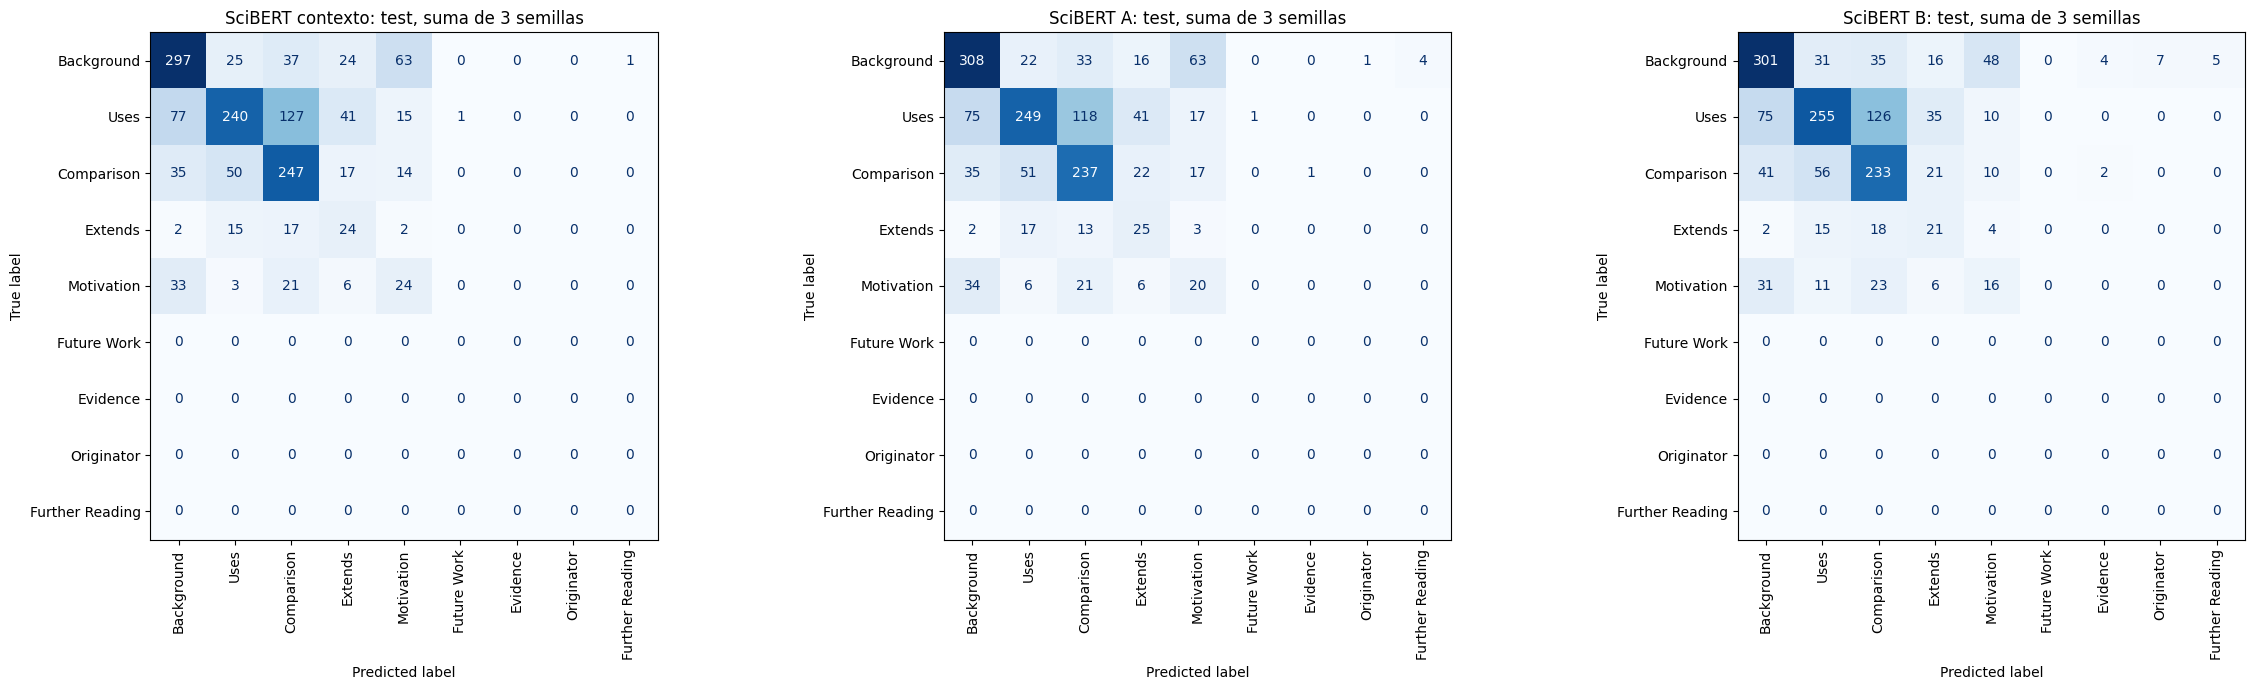

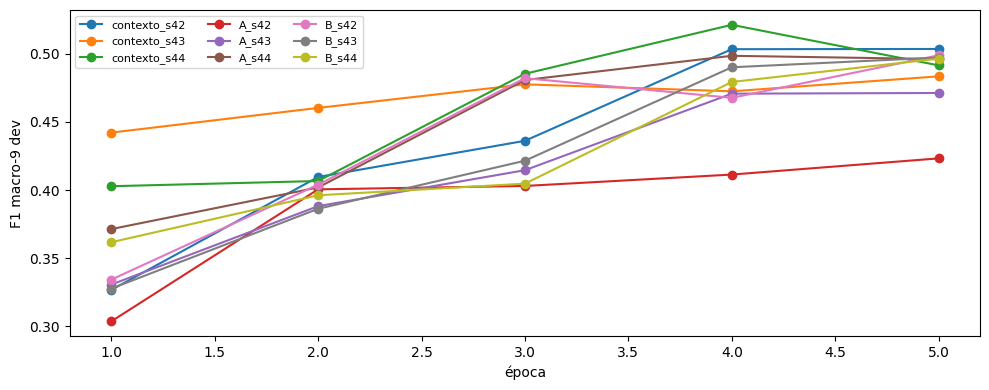

9246

In [9]:
fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(8*len(STRATEGIES), 7))
for ax, strategy in zip(axes, STRATEGIES):
    cm = sum(confusion_matrix(ids['test'], p, labels=range(K)) for p in preds[strategy])
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90)
    ax.set_title(f'SciBERT {strategy}: test, suma de {len(SEEDS)} semillas')
fig.tight_layout(); fig.savefig(OUT/'confusion.png', dpi=160, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(10,4))
for key, history in histories.items():
    ax.plot([h['epoch'] for h in history], [h['dev_f1_macro_9'] for h in history], marker='o', label=key)
ax.set_xlabel('época'); ax.set_ylabel('F1 macro-9 dev'); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'dev_curves.png', dpi=160); plt.show()
(OUT/'results.json').write_text(json.dumps({'manifest':manifest,'runs':results.to_dict(orient='records'),'tfidf':tfidf_rows,'bootstrap':bootstrap.to_dict(orient='records')},indent=2,default=float),encoding='utf-8')

## Resultados

La época de cada corrida se eligió con F1 macro-9 en dev. Los valores son el promedio de 3 semillas sobre test.

| Modelo | Entrada adicional al contexto | F1 macro 9 etiquetas | F1 macro 5 clases presentes | Exactitud |
|:--|:--|--:|--:|--:|
| SciBERT contexto | Ninguna | 0,2625 | 0,4724 | 0,5706 |
| SciBERT A | Título y abstract del citado | 0,2611 | 0,4701 | 0,5754 |
| SciBERT B | Top-3 chunks del citado | 0,2545 | 0,4582 | 0,5665 |
| TF-IDF A | Título y abstract del citado | 0,1663 | 0,2993 | 0,3745 |
| TF-IDF B | Chunks del citado | 0,1286 | 0,2315 | 0,3045 |

Bootstrap pareado sobre test (10.000 remuestreos, diferencia en F1 macro-9):

| Comparación | Diferencia | IC 95% |
|:--|--:|:--|
| B frente a A | -0,0066 | -0,0177 a 0,0050 |
| A frente a contexto | -0,0013 | -0,0152 a 0,0130 |
| B frente a contexto | -0,0079 | -0,0232 a 0,0073 |
| A frente a TF-IDF A | 0,0949 | 0,0615 a 0,1266 |
| B frente a TF-IDF B | 0,1259 | 0,0948 a 0,1550 |

**Lectura del resultado.** Las tres entradas de SciBERT superan a TF-IDF, con intervalos por encima de cero. Agregar información del documento citado (A o B) no mejora frente a usar solo el contexto, y la diferencia entre B y A no es significativa.

**Alcance.** El test tiene 486 ejemplos y solo 5 de las 9 etiquetas. El F1 macro-9 cuenta en cero las 4 clases sin soporte. En B, cerca de la mitad de las entradas supera 512 tokens y se recorta el texto del citado.